In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("student_performance.csv")
df.head()

,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department
0,101,Aarav,20,4.5,90.0,85.0,CSE
1,102,Diya,21,3.0,80.0,72.0,ECE
2,103,Kabir,19,2.0,65.0,58.0,CSE
3,104,Meera,20,5.0,95.0,92.0,IT
4,105,Rohan,22,NaN,70.0,64.0,ECE


In [4]:
print("Shape:", df.shape)
print("\\nColumns:", df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()
print("\\nStatistical summary:")
display(df.describe(include="all"))
print("\\nMissing values:")
display(df.isnull().sum())
print("\\nDuplicate rows:", df.duplicated().sum())

Shape: (20, 7)
\nColumns: ['Student_ID', 'Name', 'Age', 'Study_Hours', 'Attendance', 'Marks', 'Department']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   20 non-null     int64  
 1   Name         20 non-null     str    
 2   Age          20 non-null     int64  
 3   Study_Hours  18 non-null     float64
 4   Attendance   19 non-null     float64
 5   Marks        19 non-null     float64
 6   Department   20 non-null     str    
dtypes: float64(3), int64(2), str(2)
memory usage: 1.4 KB
\nStatistical summary:


,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department
count,20.00000,20,20.000000,18.000000,19.000000,19.000000,20
unique,NaN,19,NaN,NaN,NaN,NaN,3
top,NaN,Dev,NaN,NaN,NaN,NaN,ECE
freq,NaN,2,NaN,NaN,NaN,NaN,7
mean,110.25000,NaN,20.400000,3.555556,80.947368,74.578947,NaN
std,5.59017,NaN,0.994723,1.402612,12.699404,16.463143,NaN
min,101.00000,NaN,19.000000,1.000000,55.000000,42.000000,NaN
25%,105.75000,NaN,20.000000,2.625000,72.500000,65.500000,NaN
50%,110.50000,NaN,20.000000,3.500000,82.000000,78.000000,NaN
75%,115.00000,NaN,21.000000,4.500000,90.500000,88.500000,NaN


\nMissing values:


Student_ID     0
Name           0
Age            0
Study_Hours    2
Attendance     1
Marks          1
Department     0
dtype: int64

\nDuplicate rows: 1


In [10]:
df_clean = df.drop_duplicates().copy()

numeric_cols = ["Age", "Study_Hours", "Attendance", "Marks"]
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after cleaning:")
display(df_clean.isnull().sum())


Missing values after cleaning:


Student_ID     0
Name           0
Age            0
Study_Hours    0
Attendance     0
Marks          0
Department     0
dtype: int64

In [9]:
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
df_clean.head()

Duplicate rows after cleaning: 0


,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department
0,101,Aarav,20,4.5,90.0,85.0,CSE
1,102,Diya,21,3.0,80.0,72.0,ECE
2,103,Kabir,19,2.0,65.0,58.0,CSE
3,104,Meera,20,5.0,95.0,92.0,IT
4,105,Rohan,22,3.5,70.0,64.0,ECE


In [21]:
# Students scoring more than 70 marks
high_scorers = df_clean[df_clean["Marks"] > 70]
display(high_scorers)


,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department,Result,Attendance_Status,Study_Category
0,101,Aarav,20,4.5,90.0,85.0,CSE,Pass,Good Attendance,High
1,102,Diya,21,3.0,80.0,72.0,ECE,Pass,Good Attendance,Medium
3,104,Meera,20,5.0,95.0,92.0,IT,Pass,Good Attendance,High
5,106,Anaya,21,4.0,84.5,78.0,IT,Pass,Good Attendance,Medium
7,108,Sara,19,3.5,88.0,81.0,IT,Pass,Good Attendance,Medium
8,109,Vivaan,22,2.5,75.0,79.5,ECE,Pass,Good Attendance,Medium
9,110,Myra,20,6.0,98.0,96.0,CSE,Pass,Good Attendance,High
11,112,Kiara,19,4.5,91.0,89.0,ECE,Pass,Good Attendance,High
13,114,Aadhya,22,5.5,96.0,94.0,IT,Pass,Good Attendance,High
16,116,Saanvi,20,4.0,87.0,83.0,IT,Pass,Good Attendance,Medium


In [11]:
# Students with attendance above 75%
good_attendance = df_clean[df_clean["Attendance"] > 75]
display(good_attendance)


,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department
0,101,Aarav,20,4.5,90.0,85.0,CSE
1,102,Diya,21,3.0,80.0,72.0,ECE
3,104,Meera,20,5.0,95.0,92.0,IT
5,106,Anaya,21,4.0,84.5,78.0,IT
7,108,Sara,19,3.5,88.0,81.0,IT
9,110,Myra,20,6.0,98.0,96.0,CSE
10,111,Arjun,21,3.0,82.0,70.0,IT
11,112,Kiara,19,4.5,91.0,89.0,ECE
13,114,Aadhya,22,5.5,96.0,94.0,IT
14,115,Dev,21,3.5,78.0,67.0,ECE


In [12]:
# Students studying more than 3 hours and scoring above 60
consistent_students = df_clean[
    (df_clean["Study_Hours"] > 3) & (df_clean["Marks"] > 60)
]
display(consistent_students)

,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department
0,101,Aarav,20,4.5,90.0,85.0,CSE
3,104,Meera,20,5.0,95.0,92.0,IT
4,105,Rohan,22,3.5,70.0,64.0,ECE
5,106,Anaya,21,4.0,84.5,78.0,IT
7,108,Sara,19,3.5,88.0,81.0,IT
9,110,Myra,20,6.0,98.0,96.0,CSE
11,112,Kiara,19,4.5,91.0,89.0,ECE
13,114,Aadhya,22,5.5,96.0,94.0,IT
14,115,Dev,21,3.5,78.0,67.0,ECE
16,116,Saanvi,20,4.0,87.0,83.0,IT


In [13]:
df_clean["Result"] = np.where(df_clean["Marks"] >= 40, "Pass", "Fail")
df_clean["Attendance_Status"] = np.where(df_clean["Attendance"] >= 75, "Good Attendance", "Low Attendance")
df_clean["Study_Category"] = pd.cut(
    df_clean["Study_Hours"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Low", "Medium", "High"]
)

display(df_clean.head())

,Student_ID,Name,Age,Study_Hours,Attendance,Marks,Department,Result,Attendance_Status,Study_Category
0,101,Aarav,20,4.5,90.0,85.0,CSE,Pass,Good Attendance,High
1,102,Diya,21,3.0,80.0,72.0,ECE,Pass,Good Attendance,Medium
2,103,Kabir,19,2.0,65.0,58.0,CSE,Pass,Low Attendance,Low
3,104,Meera,20,5.0,95.0,92.0,IT,Pass,Good Attendance,High
4,105,Rohan,22,3.5,70.0,64.0,ECE,Pass,Low Attendance,Medium


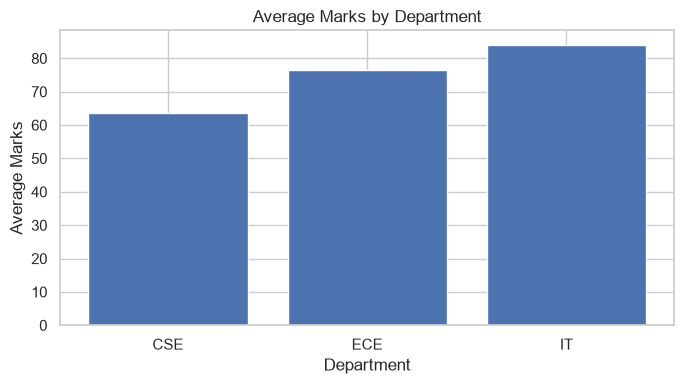

In [14]:
avg_marks = df_clean.groupby("Department")["Marks"].mean()

plt.figure(figsize=(7, 4))
plt.bar(avg_marks.index, avg_marks.values)
plt.title("Average Marks by Department")
plt.xlabel("Department")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

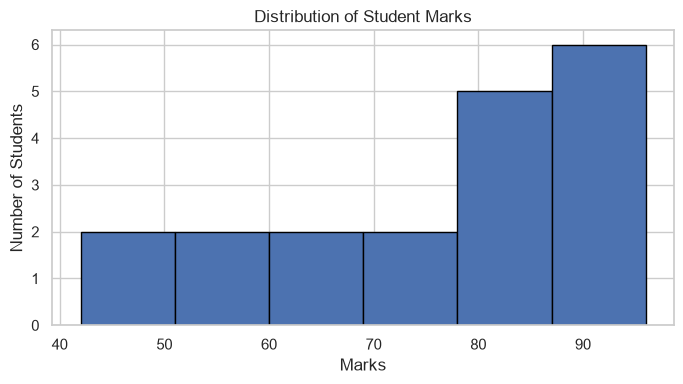

In [20]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["Marks"], bins=6, edgecolor="black")
plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

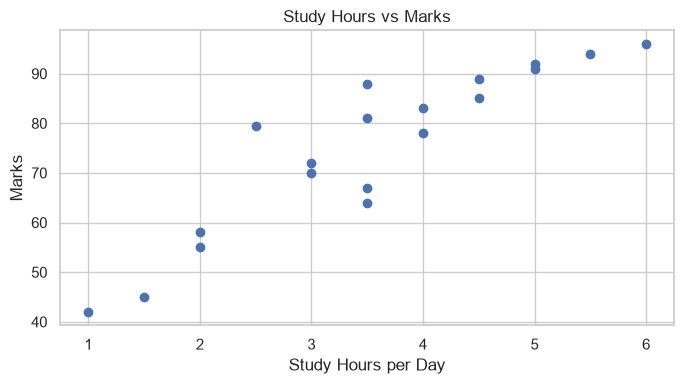

In [16]:
plt.figure(figsize=(7, 4))
plt.scatter(df_clean["Study_Hours"], df_clean["Marks"])
plt.title("Study Hours vs Marks")
plt.xlabel("Study Hours per Day")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

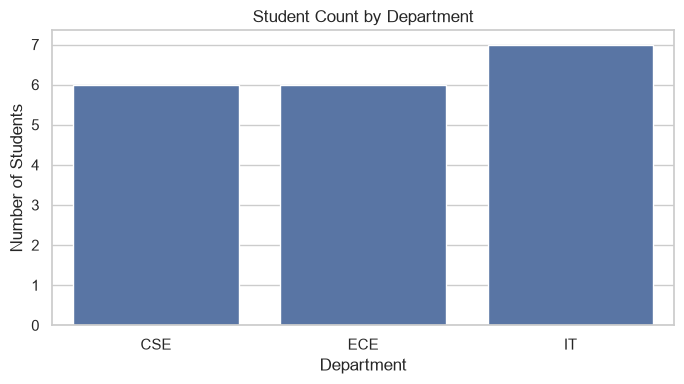

In [17]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="Department")
plt.title("Student Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

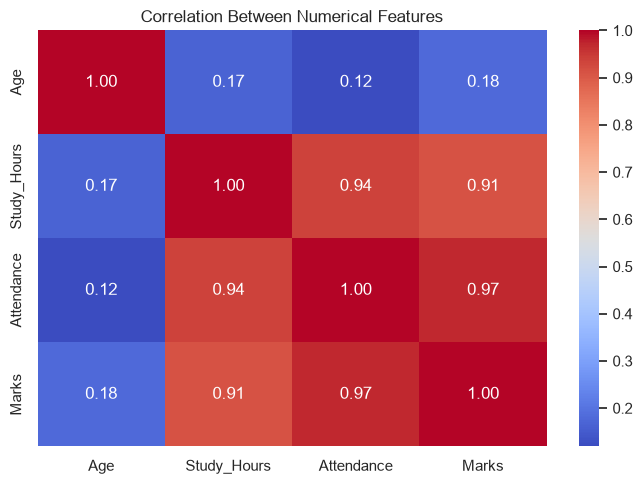

In [18]:
plt.figure(figsize=(7, 5))
correlation = df_clean[["Age", "Study_Hours", "Attendance", "Marks"]].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [19]:
cleaned_path = "cleaned_student_performance.csv"
df_clean.to_csv(cleaned_path, index=False)
print(f"Cleaned dataset saved as {cleaned_path}")

Cleaned dataset saved as cleaned_student_performance.csv
